In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("Diabetes_prediction.csv")

In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494,0
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281,0
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873,1
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868,0
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789,0


In [5]:
print("Shape:", df.shape)
df.dtypes

Shape: (1000, 9)


Pregnancies                   int64
Glucose                     float64
BloodPressure               float64
SkinThickness               float64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                         float64
Diagnosis                     int64
dtype: object

In [6]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Diagnosis                   0
dtype: int64

In [7]:
feature_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
                "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
X = df[feature_cols]
y = df["Diagnosis"]

print("Target distribution:")
print(y.value_counts())

Target distribution:
Diagnosis
0    694
1    306
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples:     {X_test.shape[0]}")
print("Feature scaling applied (StandardScaler)")

Training samples: 800
Test samples:     200
Feature scaling applied (StandardScaler)


In [9]:
svm_linear = SVC(kernel="linear", C=1.0, random_state=42)
svm_linear.fit(X_train_scaled, y_train)
y_pred_linear = svm_linear.predict(X_test_scaled)

print("SVM with Linear Kernel")
print("Accuracy:", accuracy_score(y_test, y_pred_linear) * 100, "%")

SVM with Linear Kernel
Accuracy: 69.5 %


In [10]:
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm_rbf.fit(X_train_scaled, y_train)
y_pred_rbf = svm_rbf.predict(X_test_scaled)

print("SVM with RBF Kernel")
print("Accuracy:", accuracy_score(y_test, y_pred_rbf) * 100, "%")

SVM with RBF Kernel
Accuracy: 69.5 %


In [11]:
kernels = ["linear", "rbf", "poly", "sigmoid"]
for kernel in kernels:
    svm = SVC(kernel=kernel, C=1.0, random_state=42)
    svm.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, svm.predict(X_test_scaled))
    print(f"Kernel: {kernel:>8}  |  Accuracy: {acc*100:.2f}%")

Kernel:   linear  |  Accuracy: 69.50%
Kernel:      rbf  |  Accuracy: 69.50%
Kernel:     poly  |  Accuracy: 66.50%
Kernel:  sigmoid  |  Accuracy: 66.50%


In [12]:
print("Classification Report (RBF Kernel):")
print(classification_report(y_test, y_pred_rbf, target_names=["Non-Diabetic", "Diabetic"]))

Classification Report (RBF Kernel):
              precision    recall  f1-score   support

Non-Diabetic       0.69      1.00      0.82       139
    Diabetic       0.00      0.00      0.00        61

    accuracy                           0.69       200
   macro avg       0.35      0.50      0.41       200
weighted avg       0.48      0.69      0.57       200



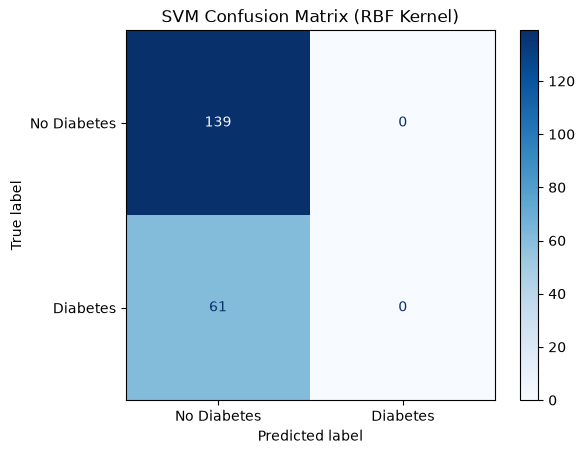

In [13]:
cm = confusion_matrix(y_test, y_pred_rbf)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
).plot(cmap="Blues")
plt.title("SVM Confusion Matrix (RBF Kernel)")
plt.show()

In [14]:
C_values = [0.01, 0.1, 1, 10, 100]
print("Effect of C parameter on RBF SVM:")
for c in C_values:
    svm = SVC(kernel="rbf", C=c, gamma="scale", random_state=42)
    svm.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, svm.predict(X_test_scaled))
    print(f"  C={c:>6}  |  Accuracy: {acc*100:.2f}%")

Effect of C parameter on RBF SVM:
  C=  0.01  |  Accuracy: 69.50%
  C=   0.1  |  Accuracy: 69.50%
  C=     1  |  Accuracy: 69.50%
  C=    10  |  Accuracy: 61.00%
  C=   100  |  Accuracy: 55.00%
